# Cross-track + temporal attention for FastKLT, distilled from CoTracker3

**Question.** FAST + KLT ("FastKLT") tracks die young. The forward–backward check fires on blur, the LK window slides onto an occluder,
and a drifting track is either dropped or kept as a zombie. Can a small transformer that lets each track look at (a) its own causal
history and (b) its spatial neighbours make tracks live longer **while staying correct**?

**Design.** CoTracker3's update transformer, transplanted onto FastKLT:
- tokens = (track, frame) over a causal window of the last `W` frames, built from KLT's own state
- temporal attention along each track with a **causal mask** (frame t sees only frames ≤ t) and a learned relative-time bias
- cross-track attention restricted to each track's **k nearest live neighbours** in the same frame, with a relative-position encoding.
  No virtual/proxy tracks: N here is ~250 sparse corners, not thousands of dense queries, so there is no bottleneck to squeeze through
- the module runs online, inside the KLT loop. Its corrections are committed before KLT steps to the next frame

**The decision under test: what do the tokens see?**

| arm | token input | can do |
|---|---|---|
| **M** (motion) | KLT trajectory, flow, LK residual, forward–backward error, age | weight + reject (plus a motion-consensus correction, tested separately) |
| **I** (image) | M + CoTracker3-style 4D local correlation from CoTracker3's frozen `fnet` + `corr_mlp` | correct position + weight + reject |

Both arms share architecture, heads and training. Only the token input differs.

**Teacher.** Offline CoTracker3 (scaled checkpoint) tracks every FAST seed the tracker could ever spawn. Its positions supervise the
correction head. Its visibility, plus "within δ px", supervises keep/drop. Training starts open-loop (plain KLT trajectories), then gets
one DAgger round of closed-loop rollouts, because corrections change what KLT sees next.

**Benchmark.** 30 TAP-Vid-DAVIS clips, unseen in training (training uses DAVIS-2017 train). Headline metric: **valid lifespan**, the
number of frames from birth until a track is dropped, occluded, or more than δ px from the teacher. Tracks still correct at the end of a
clip are censored (Kaplan–Meier). Raw lifespan alone is gameable (never drop anything), so every number is paired with **track
precision** (share of alive track-frames that are correct), and keep thresholds are swept into Pareto curves. A teacher-free check
repeats the benchmark on TAP-Vid's human-labelled points.

Runs on a Colab T4. Every expensive step caches to `/content/cta_cache`, so cells can be re-run after a disconnect.

In [1]:
import os, sys, glob, math, time, random, pickle, shutil, zipfile, urllib.request
from dataclasses import dataclass
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = "/content" if os.path.isdir("/content") else os.path.abspath(".")
DATA = f"{ROOT}/cta_data"      # raw downloads
CACHE = f"{ROOT}/cta_cache"    # everything expensive is cached here
for d in ("frames", "labels", "superset", "rollouts", "ckpt", "bench"):
    os.makedirs(f"{CACHE}/{d}", exist_ok=True)
os.makedirs(DATA, exist_ok=True)
cv2.setNumThreads(os.cpu_count())

def fetch(url, path):
    """Download url to path. Writes to a .part file first, so an interrupted download never looks finished."""
    if os.path.exists(path):
        return path
    with urllib.request.urlopen(url) as r, open(path + ".part", "wb") as f:
        total = int(r.headers.get("Content-Length") or 0)
        with tqdm(total=total, unit="B", unit_scale=True, desc=os.path.basename(path)) as bar:
            while chunk := r.read(1 << 20):
                f.write(chunk)
                bar.update(len(chunk))
    os.replace(path + ".part", path)
    return path

# CoTracker source, imported straight from the repo snapshot (no pip install, no kernel restart)
COTRACKER_DIR = f"{CACHE}/co-tracker-main"
if not os.path.isdir(COTRACKER_DIR):
    with zipfile.ZipFile(fetch("https://github.com/facebookresearch/co-tracker/archive/refs/heads/main.zip", f"{CACHE}/co-tracker.zip")) as z:
        z.extractall(CACHE)
sys.path.insert(0, COTRACKER_DIR)
import cotracker  # noqa: E402,F401

print(f"python {sys.version.split()[0]} | torch {torch.__version__} | {device} {torch.cuda.get_device_name(0) if device == 'cuda' else ''} | "
      f"cotracker from {os.path.dirname(cotracker.__file__)}")
if device != "cuda":
    print("WARNING: no GPU. Select the Colab kernel with a T4 runtime; the teacher and training are far too slow on CPU.")

co-tracker.zip: 0.00B [00:00, ?B/s]

python 3.13.16 | torch 2.11.0+cpu | cpu  | cotracker from /content/cta_cache/co-tracker-main/cotracker


In [ ]:
@dataclass
class Cfg:
    H: int = 360                 # working resolution (DAVIS is 480x854, same aspect)
    W: int = 640
    # FastKLT
    fast_thresh: int = 20
    grid_rows: int = 12          # at most one FAST seed per grid cell per detection
    grid_cols: int = 20
    border: int = 12
    detect_every: int = 6        # fixed re-detection schedule, so the teacher can label every seed ahead of time
    min_remaining: int = 8       # no detection in the last few frames of a clip
    max_tracks: int = 256
    min_dist: float = 10.0       # a new seed must be this far from every live track
    lk_win: int = 21
    lk_levels: int = 3
    oob_margin: float = 2.0
    # supervision / metrics
    delta_valid: float = 6.0     # px: a track-frame is correct if teacher-visible and within this of the teacher
    r_max: float = 16.0          # px: larger KLT errors are only rejected, not corrected
    # module
    window: int = 16
    d_model: int = 128
    heads: int = 4
    depth: int = 3               # (causal time block, kNN space block) pairs
    knn: int = 16
    iters_image: int = 2         # CoTracker-style refinement iterations, image arm
    max_window_tracks: int = 384

cfg = Cfg()
STRIDE, CORR_LEVELS, CORR_R = 4, 4, 3     # CoTracker3's fnet stride, pyramid levels, correlation radius

## Data
Training clips: DAVIS-2017 train (60 clips, split 50 train / 10 val). Benchmark: the 30 TAP-Vid-DAVIS clips (= DAVIS-2017 val), which also
carry human-labelled point tracks. Every clip is resized to 360x640 once and stored as uint8 `.npy`.

In [4]:
DAVIS_URL = "https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip"
TAPVID_URL = "https://storage.googleapis.com/dm-tapnet/tapvid_davis.zip"

def download(url):
    zip_path = f"{DATA}/{os.path.basename(url)}"
    if not os.path.exists(zip_path + ".done"):
        with zipfile.ZipFile(fetch(url, zip_path)) as z:
            z.extractall(DATA)
        open(zip_path + ".done", "w").close()
        os.remove(zip_path)

def resize_frames(frames):
    return np.stack([cv2.resize(f, (cfg.W, cfg.H), interpolation=cv2.INTER_AREA) for f in frames])

def frames_path(name):
    return f"{CACHE}/frames/{name}.npy"

download(DAVIS_URL)
download(TAPVID_URL)

davis_train = open(f"{DATA}/DAVIS/ImageSets/2017/train.txt").read().split()
for name in tqdm(davis_train, desc="DAVIS train"):
    if not os.path.exists(frames_path(name)):
        files = sorted(glob.glob(f"{DATA}/DAVIS/JPEGImages/480p/{name}/*.jpg"))
        np.save(frames_path(name), resize_frames([cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB) for f in files]))

gt_path = f"{CACHE}/tapvid_gt.pkl"
if os.path.exists(gt_path):
    GT = pickle.load(open(gt_path, "rb"))
else:
    GT = {}   # TAP-Vid labels at working resolution: points (N, T, 2) px, occluded (N, T)
    tapvid = pickle.load(open(glob.glob(f"{DATA}/**/tapvid_davis.pkl", recursive=True)[0], "rb"))
    for name, d in tqdm(tapvid.items(), desc="TAP-Vid DAVIS"):
        video = d["video"]
        if isinstance(video[0], bytes):
            video = [cv2.cvtColor(cv2.imdecode(np.frombuffer(f, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB) for f in video]
        np.save(frames_path(name), resize_frames(video))
        GT[name] = dict(points=(d["points"] * np.array([cfg.W - 1, cfg.H - 1])).astype(np.float32),
                        occluded=d["occluded"].astype(bool))
    pickle.dump(GT, open(gt_path, "wb"))
    del tapvid

names = sorted(davis_train)
random.Random(0).shuffle(names)
VAL, TRAIN, TEST = sorted(names[:10]), sorted(names[10:]), sorted(GT)
assert not set(TEST) & set(davis_train)
lengths = {n: np.load(frames_path(n), mmap_mode="r").shape[0] for n in TRAIN + VAL + TEST}
print(f"{len(TRAIN)} train / {len(VAL)} val / {len(TEST)} test clips; frames per clip "
      f"min {min(lengths.values())} / mean {np.mean(list(lengths.values())):.0f} / max {max(lengths.values())}")

DAVIS-2017-trainval-480p.zip:   0%|          | 0.00/833M [00:00<?, ?B/s]

tapvid_davis.zip:   0%|          | 0.00/1.67G [00:00<?, ?B/s]

DAVIS train:   0%|          | 0/60 [00:00<?, ?it/s]

TAP-Vid DAVIS:   0%|          | 0/30 [00:00<?, ?it/s]

50 train / 10 val / 30 test clips; frames per clip min 25 / mean 69 / max 104


## FastKLT
FAST corners (the strongest one per grid cell) plus pyramidal Lucas–Kanade with a forward–backward check. Re-detection runs on a fixed
schedule (every 6 frames). That way the set of seeds the tracker could ever spawn depends only on the clip, not on which tracks are alive,
and the teacher can label all of them ahead of time. A new seed is admitted only if it is ≥ 10 px from every live track and fewer than
256 tracks are alive.

In [5]:
FAST = cv2.FastFeatureDetector_create(threshold=cfg.fast_thresh, nonmaxSuppression=True)
LK = dict(winSize=(cfg.lk_win, cfg.lk_win), maxLevel=cfg.lk_levels,
          criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))

def load_video(name):
    frames = np.load(frames_path(name))
    return frames, np.stack([cv2.cvtColor(f, cv2.COLOR_RGB2GRAY) for f in frames])

def detection_frames(T):
    return [t for t in range(0, T, cfg.detect_every) if T - t >= cfg.min_remaining]

def detect_seeds(gray):
    kps = FAST.detect(gray, None)
    if not kps:
        return np.zeros((0, 3), np.float32)
    pts = np.array([k.pt for k in kps], np.float32)
    resp = np.array([k.response for k in kps], np.float32)
    b = cfg.border
    keep = (pts[:, 0] >= b) & (pts[:, 0] < cfg.W - b) & (pts[:, 1] >= b) & (pts[:, 1] < cfg.H - b)
    pts, resp = pts[keep], resp[keep]
    cell = (pts[:, 1] * cfg.grid_rows / cfg.H).astype(int) * cfg.grid_cols + (pts[:, 0] * cfg.grid_cols / cfg.W).astype(int)
    order = np.lexsort((-resp, cell))                       # by cell, strongest first
    best = order[np.r_[True, cell[order][1:] != cell[order][:-1]]]
    best = best[np.argsort(-resp[best])]                    # strongest seeds get admitted first
    return np.c_[pts[best], resp[best]]

def video_seeds(gray):
    """Every seed the tracker may spawn: rows of (t0, x, y, FAST response)."""
    rows = []
    for t in detection_frames(len(gray)):
        s = detect_seeds(gray[t])
        rows.append(np.c_[np.full((len(s), 1), t), s])
    return np.concatenate(rows).astype(np.float32)

def in_bounds(p, margin=cfg.oob_margin):
    return (np.isfinite(p).all(-1) & (p[..., 0] >= margin) & (p[..., 0] <= cfg.W - 1 - margin)
            & (p[..., 1] >= margin) & (p[..., 1] <= cfg.H - 1 - margin))

def klt_step(g0, g1, p0):
    """Track p0 (N, 2) from frame g0 to g1. Returns new positions, LK status, LK residual, forward-backward error."""
    p0 = np.ascontiguousarray(p0, np.float32).reshape(-1, 1, 2)
    p1, st, err = cv2.calcOpticalFlowPyrLK(g0, g1, p0, None, **LK)
    pb, stb, _ = cv2.calcOpticalFlowPyrLK(g1, g0, p1, None, **LK)
    p0, p1, pb = p0[:, 0], p1[:, 0], pb[:, 0]
    status = (st[:, 0] == 1) & (stb[:, 0] == 1) & np.isfinite(p1).all(-1)
    p1 = np.where(np.isfinite(p1), p1, p0)
    fb = np.nan_to_num(np.linalg.norm(pb - p0, axis=-1), nan=1e3, posinf=1e3)
    return p1, status, np.nan_to_num(err[:, 0], nan=1e3, posinf=1e3), fb

def admit(cand_xy, live_xy, n_live):
    """Greedy admission of candidates (sorted strongest first): cap + min-distance. Returns a bool mask over candidates."""
    ok = np.zeros(len(cand_xy), bool)
    pts = np.asarray(live_xy, np.float32).reshape(-1, 2)
    for j, p in enumerate(cand_xy):
        if n_live >= cfg.max_tracks:
            break
        if len(pts) == 0 or np.min(np.sum((pts - p) ** 2, -1)) >= cfg.min_dist ** 2:
            ok[j] = True
            pts = np.vstack([pts, p[None]])
            n_live += 1
    return ok

_, g = load_video(TRAIN[0])
print(f"{TRAIN[0]}: {len(g)} frames, {len(video_seeds(g))} seeds over {len(detection_frames(len(g)))} detections")

bear: 82 frames, 2811 seeds over 13 detections


## Teacher: CoTracker3 labels for every seed
Offline CoTracker3 tracks the seeds from each detection frame forward over the rest of the clip. Seeds from the same detection frame are
tracked jointly (≤ 240 per call). Labels: positions `q (T, Ns, 2)` and visibility `vis (T, Ns)` (CoTracker's own threshold, 0.9).
Both are NaN/False before birth.

In [7]:
from cotracker.predictor import CoTrackerPredictor

CKPT = fetch("https://huggingface.co/facebook/cotracker3/resolve/main/scaled_offline.pth", f"{CACHE}/scaled_offline.pth")
teacher = CoTrackerPredictor(checkpoint=None, offline=True, window_len=60)
state = torch.load(CKPT, map_location="cpu", weights_only=False)
teacher.model.load_state_dict(state.get("model", state))
teacher = teacher.to(device).eval()
for p in teacher.parameters():
    p.requires_grad_(False)

@torch.no_grad()
def teacher_tracks(frames, queries):
    """frames (T, H, W, 3) uint8, queries (N, 3) of (t, x, y) px -> positions (T, N, 2), visibility (T, N)."""
    video = torch.from_numpy(frames).to(device).permute(0, 3, 1, 2)[None].float()
    tr, vi = teacher(video, queries=torch.from_numpy(queries).float().to(device)[None])
    return tr[0].cpu().numpy(), vi[0].cpu().numpy()

def label_video(name):
    path = f"{CACHE}/labels/{name}.npz"
    if os.path.exists(path):
        return dict(np.load(path))
    frames, gray = load_video(name)
    seeds = video_seeds(gray)
    T, Ns = len(frames), len(seeds)
    q, vis = np.full((T, Ns, 2), np.nan, np.float32), np.zeros((T, Ns), bool)
    for t0 in np.unique(seeds[:, 0]).astype(int):
        idx = np.where(seeds[:, 0] == t0)[0]
        tr, vi = teacher_tracks(frames[t0:], np.c_[np.zeros(len(idx)), seeds[idx, 1:3]].astype(np.float32))
        q[t0:, idx], vis[t0:, idx] = tr, vi
    out = dict(seeds=seeds, q=q, vis=vis)
    np.savez_compressed(path, **out)
    return out

t_start = time.time()
for name in tqdm(TRAIN + VAL + TEST, desc="teacher"):
    label_video(name)
print(f"teacher labels ready ({time.time() - t_start:.0f}s)")

teacher:   0%|          | 0/90 [00:00<?, ?it/s]

teacher labels ready (2172s)


### How good is the teacher?
On the benchmark clips, compare CoTracker3 with TAP-Vid's human labels (each point queried at its first visible frame; errors in px at
360x640). This is the noise floor under every teacher-relative number below.

In [8]:
def gt_probes(name):
    """TAP-Vid points as extra seeds, queried at their first visible frame: probes (P, 3), q (T, P, 2), vis (T, P)."""
    pts, occ = GT[name]["points"], GT[name]["occluded"]
    keep = (~occ).any(1)
    pts, occ = pts[keep], occ[keep]
    t0 = (~occ).argmax(1)
    probes = np.c_[t0, pts[np.arange(len(pts)), t0]].astype(np.float32)
    ok = in_bounds(probes[:, 1:3])
    return probes[ok], pts[ok].transpose(1, 0, 2), ~occ[ok].T

def teacher_vs_gt():
    errs, vis_acc = [], []
    for name in TEST:
        probes, q, vis = gt_probes(name)
        tr, vi = teacher_tracks(np.load(frames_path(name)), probes)
        after = np.arange(len(q))[:, None] > probes[None, :, 0]
        errs.append(np.linalg.norm(tr - q, axis=-1)[after & vis])
        vis_acc.append((vi == vis)[after])
    e = np.concatenate(errs)
    print(f"teacher vs TAP-Vid GT, visible points: median error {np.median(e):.2f}px; "
          + ", ".join(f"within {d}px {np.mean(e < d):.1%}" for d in (3, 6, 12))
          + f"; visibility accuracy {np.concatenate(vis_acc).mean():.1%}")

teacher_vs_gt()

teacher vs TAP-Vid GT, visible points: median error 2.38px; within 3px 58.6%, within 6px 80.1%, within 12px 90.7%; visibility accuracy 86.9%


## Open-loop KLT for every seed
LK tracks each point on its own, so one pass of plain KLT over all seeds (keep everything, stop only when a point leaves the image) gives
the exact trajectory any reject-only policy would see. This "superset" is the round-0 training data.

In [9]:
def klt_superset(gray, seeds):
    T, Ns = len(gray), len(seeds)
    raw = np.full((T, Ns, 2), np.nan, np.float32)
    status, err, fb = np.zeros((T, Ns), bool), np.zeros((T, Ns), np.float32), np.zeros((T, Ns), np.float32)
    t0 = seeds[:, 0].astype(int)
    alive = np.zeros(Ns, bool)
    for t in range(T):
        if t > 0 and alive.any():
            idx = np.where(alive)[0]
            p1, s, e, f = klt_step(gray[t - 1], gray[t], raw[t - 1, idx])
            ok = in_bounds(p1)
            alive[idx[~ok]] = False
            idx = idx[ok]
            raw[t, idx], status[t, idx], err[t, idx], fb[t, idx] = p1[ok], s[ok], e[ok], f[ok]
        born = t0 == t
        raw[t, born], status[t, born] = seeds[born, 1:3], True
        alive |= born
    return dict(raw=raw, status=status, err=err, fb=fb)

def superset(name):
    path = f"{CACHE}/superset/{name}.npz"
    if os.path.exists(path):
        return dict(np.load(path))
    out = klt_superset(load_video(name)[1], label_video(name)["seeds"])
    np.savez_compressed(path, **out)
    return out

for name in tqdm(TRAIN + VAL, desc="KLT superset"):
    superset(name)

KLT superset:   0%|          | 0/60 [00:00<?, ?it/s]

### Which tracks are alive? Replaying the tracker's admission logic
A training window has to look like what the module sees at run time: only tracks that were admitted (cap + min-distance) and not yet
dropped, together with their neighbours. `simulate_alive` replays admission on the open-loop trajectories under a given death rule:
- *oracle + delay*: die g frames after first going wrong, g random per track. These windows show the failure onsets the module must catch.
- *heuristic*: die at the first failed status / forward–backward check, like FastKLT itself.

In [10]:
def simulate_alive(seeds, raw, death):
    """exists (T, Ns): track alive at t (token present). death (Ns,): frame of a track's last token."""
    T, Ns = raw.shape[:2]
    t0 = seeds[:, 0].astype(int)
    exists, alive = np.zeros((T, Ns), bool), np.zeros(Ns, bool)
    for t in range(T):
        alive &= np.isfinite(raw[t, :, 0])
        new = np.where(t0 == t)[0]
        if len(new):
            alive[new[admit(seeds[new, 1:3], raw[t, alive], alive.sum())]] = True
        exists[t] = alive
        alive &= death != t
    return exists

def first_after_birth(bad, t0):
    """First frame > t0 where bad (T, Ns) holds; T if never."""
    b = bad & (np.arange(bad.shape[0])[:, None] > t0[None])
    return np.where(b.any(0), b.argmax(0), bad.shape[0])

def alive_variants(lab, sup, rng):
    t0 = lab["seeds"][:, 0].astype(int)
    wrong = ~lab["vis"] | ~(np.linalg.norm(sup["raw"] - lab["q"], axis=-1) < cfg.delta_valid)
    first_wrong = first_after_birth(wrong, t0)
    out = [simulate_alive(lab["seeds"], sup["raw"], first_wrong + rng.integers(lo, hi + 1, len(t0)))
           for lo, hi in ((0, 3), (0, 3), (4, 12))]
    for fb_thresh in (0.5, 2.0):
        bad = ~sup["status"] | (sup["fb"] > fb_thresh)
        out.append(simulate_alive(lab["seeds"], sup["raw"], first_after_birth(bad, t0)))
    return out

def open_loop_source(name, rng):
    lab, sup = label_video(name), superset(name)
    raw = sup["raw"]
    prev = np.roll(raw, 1, axis=0)
    prev[0] = np.nan
    t0 = lab["seeds"][:, 0].astype(int)
    prev[t0, np.arange(len(t0))] = lab["seeds"][:, 1:3]
    return dict(seeds=lab["seeds"], raw=raw, prev=prev, prevraw=prev, status=sup["status"], err=sup["err"], fb=sup["fb"],
                q=lab["q"], vis=lab["vis"], variants=alive_variants(lab, sup, rng))

## Tokens
A window is the last `W` frames ending at `t`. It holds every track alive at any of those frames. All inputs come from the tracker's own
state, so training windows (from the superset or from closed-loop logs) and run-time windows go through the same `make_window`.

Motion features per token (both arms): KLT flow from the previous committed position, the correction committed at the previous frame,
displacement since birth, absolute position, LK residual, forward–backward error, LK status, age. Displacements use CoTracker3's
Fourier encoding.

In [11]:
WIN_KEYS = ("raw", "prev", "prevraw", "status", "err", "fb")

def make_window(src, exists, t, max_tracks=None, rng=None):
    W = cfg.window
    s0 = max(0, t - W + 1)
    cols = np.where(exists[s0:t + 1].any(0))[0]
    if max_tracks is not None and len(cols) > max_tracks:
        cols = np.sort(rng.choice(cols, max_tracks, replace=False))
    pad = W - (t + 1 - s0)
    def take(a):
        x = a[s0:t + 1][:, cols]
        return np.concatenate([np.zeros((pad,) + x.shape[1:], x.dtype), x]) if pad else x
    win = {k: take(src[k]) for k in WIN_KEYS}
    win.update(exists=take(exists), frame=np.r_[np.zeros(pad, int), np.arange(s0, t + 1)], seed=src["seeds"][cols, :3], cols=cols)
    if "q" in src:
        win["q"], win["vis"] = take(src["q"]), take(src["vis"])
    return win

def collate(wins):
    N = max(len(w["cols"]) for w in wins)
    def stack(key, axis):
        xs = []
        for w in wins:
            x = w[key]
            if x.dtype.kind == "f":
                x = np.nan_to_num(x)
            widths = [(0, 0)] * x.ndim
            widths[axis] = (0, N - x.shape[axis])
            xs.append(np.pad(x, widths))
        return torch.from_numpy(np.stack(xs)).to(device)
    b = {k: stack(k, 1) for k in WIN_KEYS + ("exists", "q", "vis") if k in wins[0]}
    b["seed"] = stack("seed", 0).float()
    b["cols"] = stack("cols", 0).long()
    b["frame"] = torch.from_numpy(np.stack([w["frame"] for w in wins])).long().to(device)
    return b

def posenc(x, min_deg, max_deg):
    """CoTracker3's Fourier encoding: [x, sin(2^k x), cos(2^k x)], k in [min_deg, max_deg)."""
    scales = 2.0 ** torch.arange(min_deg, max_deg, device=x.device, dtype=x.dtype)
    xb = (x[..., None, :] * scales[:, None]).flatten(-2)
    return torch.cat([x, torch.sin(torch.cat([xb, xb + 0.5 * math.pi], -1))], -1)

MOTION_DIM = 42 + 42 + 34 + 18 + 5
WH = torch.tensor([cfg.W, cfg.H], device=device, dtype=torch.float32)

def motion_features(b):
    raw, prev, prevraw = b["raw"], b["prev"], b["prevraw"]
    age = (b["frame"][:, :, None] - b["seed"][:, None, :, 0]).clamp(min=0)
    x = torch.cat([posenc((raw - prev) / WH, 0, 10),                       # KLT flow from the committed position
                   posenc((prev - prevraw) / WH, 0, 10),                   # correction committed at t-1
                   posenc((raw - b["seed"][:, None, :, 1:3]) / WH, 0, 8),  # displacement since birth
                   posenc(raw / WH, 0, 4),                                 # where in the image
                   torch.log1p(b["err"].clamp(0, 1e3))[..., None] / 4,
                   torch.log1p(b["fb"].clamp(0, 1e3))[..., None],
                   b["status"].float()[..., None],
                   (age == 0).float()[..., None],
                   torch.log1p(age)[..., None] / math.log(64)], -1)
    return x * b["exists"][..., None]

### Image tokens (arm I): CoTracker3's own correlation features, frozen
Feature maps come from CoTracker3's `fnet` (stride 4, L2-normalised, 4-level pyramid). A track's template is the 7x7 support patch
around its seed at birth. Each token correlates that patch with the 7x7 patch around its current estimate: 49 x 49 = 2401 numbers per
level. CoTracker3's pretrained `corr_mlp` compresses those to 256 per level, so 1024 per token. Both modules stay frozen. Only a linear
projection into the transformer is trained. The cell ends by checking the result against CoTracker3's own implementation.

In [12]:
fnet, corr_mlp = teacher.model.fnet, teacher.model.corr_mlp
_lin = torch.linspace(-CORR_R, CORR_R, 2 * CORR_R + 1, device=device)
# same patch order as CoTracker3's get_support_points: the first axis offsets x, the second offsets y
PATCH = torch.stack(torch.meshgrid(_lin, _lin, indexing="ij"), -1).reshape(-1, 2)

@torch.no_grad()
def feature_pyramid(frames, chunk=16):
    """frames (T, H, W, 3) uint8 -> CORR_LEVELS tensors (T, 128, h, w), fp16."""
    out = []
    for i in range(0, len(frames), chunk):
        x = torch.from_numpy(frames[i:i + chunk]).to(device).permute(0, 3, 1, 2).float()
        with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
            f = fnet(2 * (x / 255.0) - 1.0)
        out.append(F.normalize(f.float(), dim=1, eps=1e-6).half())
    pyr = [torch.cat(out)]
    for _ in range(CORR_LEVELS - 1):
        pyr.append(F.avg_pool2d(pyr[-1], 2, stride=2))
    return pyr

def sample_patches(fmap, xy):
    """fmap (B, C, h, w), xy (B, N, 2) in feature pixels -> (B, N, 49, C). Bilinear, border padding, align_corners (as CoTracker3)."""
    _, _, h, w = fmap.shape
    p = xy[:, :, None, :] + PATCH
    grid = torch.stack([2 * p[..., 0] / (w - 1) - 1, 2 * p[..., 1] / (h - 1) - 1], -1)
    out = F.grid_sample(fmap, grid.to(fmap.dtype), mode="bilinear", padding_mode="border", align_corners=True)
    return out.permute(0, 2, 3, 1)

@torch.no_grad()
def seed_templates(pyr, seeds):
    """Support patches around each seed at its birth frame: (Ns, CORR_LEVELS, 49, 128) fp16."""
    seeds = torch.as_tensor(np.asarray(seeds)[:, :3], dtype=torch.float32, device=device)
    out = torch.zeros(len(seeds), CORR_LEVELS, 49, pyr[0].shape[1], device=device, dtype=torch.float16)
    for t in seeds[:, 0].unique().long().tolist():
        idx = torch.where(seeds[:, 0] == t)[0]
        for l in range(CORR_LEVELS):
            out[idx, l] = sample_patches(pyr[l][t:t + 1], seeds[None, idx, 1:3] / (STRIDE * 2 ** l))[0].half()
    return out

@torch.no_grad()
def corr_features(pyr, tmpl, frame, xy):
    """pyr from feature_pyramid, tmpl (B, N, L, 49, C), frame (B, W), xy (B, W, N, 2) px -> (B, W, N, 1024)."""
    B, W, N, _ = xy.shape
    embs = []
    with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
        for l in range(CORR_LEVELS):
            tgt = sample_patches(pyr[l][frame.flatten()], xy.reshape(B * W, N, 2) / (STRIDE * 2 ** l))
            tp = tmpl[:, None, :, l].expand(B, W, N, 49, tmpl.shape[-1]).reshape(B * W, N, 49, -1)
            corr = torch.einsum("bnpc,bnqc->bnpq", tgt.half(), tp)          # target patch x template patch
            embs.append(corr_mlp(corr.reshape(B * W * N, -1)).reshape(B, W, N, -1))
    return torch.cat(embs, -1).float()

with torch.no_grad():   # check against CoTracker3's get_track_feat / get_correlation_feat / corr_mlp
    m = teacher.model
    pyr = feature_pyramid(load_video(TRAIN[0])[0][:8])
    sd = torch.tensor([[2, 100.3, 50.7], [5, 300.0, 200.2], [2, 600.5, 340.1]], device=device)
    xy = sd[None, None, :, 1:3].repeat(1, 8, 1, 1) + 3 * torch.randn(1, 8, 3, 2, device=device)
    mine = corr_features(pyr, seed_templates(pyr, sd.cpu().numpy())[None], torch.arange(8, device=device)[None], xy)
    ref = []
    for l in range(CORR_LEVELS):
        fm = pyr[l].float()[None]
        _, sup = m.get_track_feat(fm, sd[None, :, 0].long(), sd[None, :, 1:3] / (STRIDE * 2 ** l), support_radius=CORR_R)
        sup = sup.view(1, 1, 7, 7, 3, -1).squeeze(1).permute(0, 3, 1, 2, 4)
        cf = m.get_correlation_feat(fm, (xy / (STRIDE * 2 ** l)).view(8, 3, 2))
        ref.append(m.corr_mlp(torch.einsum("btnhwc,bnijc->btnhwij", cf, sup).reshape(24, -1)).reshape(1, 8, 3, -1))
    ref = torch.cat(ref, -1)
    print(f"corr features vs CoTracker3: max abs diff {(mine - ref).abs().max().item():.2e} (mean |ref| {ref.abs().mean().item():.2e})")
    del pyr

corr features vs CoTracker3: max abs diff 8.95e-02 (mean |ref| 5.11e-01)


## The module
Each refinement iteration runs `depth` pairs of blocks, like CoTracker3's update transformer:
1. **Causal time block.** Self-attention along each track's own window. Frame t may attend to frame s only if s ≤ t and the track was
   alive at s. A learned per-head bias on t − s replaces absolute time embeddings, so it doesn't matter where the window starts.
2. **kNN space block.** In each frame, every live track attends to its k nearest live tracks (itself included). The neighbour's relative
   position goes through an MLP that adds to the value and gives a per-head attention bias. Cost is O(N·k), with no proxy tokens.

Heads per token: a Δxy correction, a visibility logit, a confidence logit for the corrected position, and a confidence logit for the raw
KLT position (used when corrections are switched off). Keep score = σ(vis)·σ(conf). It doubles as the track's weight.

In [13]:
class Mlp(nn.Sequential):
    def __init__(self, d_in, d_hidden, d_out):
        super().__init__(nn.Linear(d_in, d_hidden), nn.GELU(), nn.Linear(d_hidden, d_out))

class CausalTimeBlock(nn.Module):
    def __init__(self, d, heads, window):
        super().__init__()
        self.h = heads
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.rel_bias = nn.Parameter(torch.zeros(heads, window))
        self.mlp = Mlp(d, 4 * d, d)

    def forward(self, x, exists):
        B, W, N, d = x.shape
        h = x.permute(0, 2, 1, 3).reshape(B * N, W, d)
        e = exists.permute(0, 2, 1).reshape(B * N, W)
        q, k, v = self.qkv(self.norm1(h)).view(B * N, W, 3, self.h, d // self.h).permute(2, 0, 3, 1, 4)
        i = torch.arange(W, device=x.device)
        lag = i[:, None] - i[None, :]                                        # query frame - key frame
        allowed = ((lag >= 0) & e[:, None, :]) | torch.eye(W, dtype=torch.bool, device=x.device)
        mask = self.rel_bias[:, lag.clamp(min=0)][None].masked_fill(~allowed[:, None], float("-inf"))
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask.to(q.dtype))
        h = h + self.proj(out.transpose(1, 2).reshape(B * N, W, d))
        h = h + self.mlp(self.norm2(h))
        return h.view(B, N, W, d).permute(0, 2, 1, 3)

class KnnSpaceBlock(nn.Module):
    def __init__(self, d, heads, k):
        super().__init__()
        self.h, self.k = heads, k
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.q, self.kv, self.proj = nn.Linear(d, d), nn.Linear(d, 2 * d), nn.Linear(d, d)
        self.rel = Mlp(34, 64, d + heads)          # relative position -> value offset + per-head bias
        self.mlp = Mlp(d, 4 * d, d)

    def forward(self, x, xy, exists):
        B, W, N, d = x.shape
        H, dh, k = self.h, d // self.h, min(self.k, N)
        xs, ps, es = x.reshape(B * W, N, d), xy.reshape(B * W, N, 2).float(), exists.reshape(B * W, N)
        dist = torch.cdist(ps, ps).masked_fill(~es[:, None, :], float("inf"))
        nd, nidx = dist.topk(k, dim=-1, largest=False)                       # (BW, N, k)
        bidx = torch.arange(B * W, device=x.device)[:, None, None]
        hn = self.norm1(xs)
        kv = self.kv(hn)[bidx, nidx]                                         # (BW, N, k, 2d)
        r = self.rel(posenc((ps[bidx, nidx] - ps[:, :, None]) / WH, 0, 8))
        kn = kv[..., :d].reshape(B * W, N, k, H, dh)
        vn = (kv[..., d:] + r[..., :d]).reshape(B * W, N, k, H, dh)
        q = self.q(hn).view(B * W, N, H, dh)
        logits = torch.einsum("bnhc,bnkhc->bnhk", q, kn) / math.sqrt(dh) + r[..., d:].permute(0, 1, 3, 2)
        logits = logits.masked_fill(~torch.isfinite(nd)[:, :, None, :], -1e4)
        out = torch.einsum("bnhk,bnkhc->bnhc", logits.softmax(-1).to(vn.dtype), vn).reshape(B * W, N, d)
        xs = xs + self.proj(out)
        xs = xs + self.mlp(self.norm2(xs))
        return xs.view(B, W, N, d)

class TrackRefiner(nn.Module):
    def __init__(self, use_image, cross_track=True, d=cfg.d_model, heads=cfg.heads, depth=cfg.depth):
        super().__init__()
        self.use_image, self.cross_track = use_image, cross_track
        self.iters = cfg.iters_image if use_image else 1
        self.inp, self.delta_in = nn.Linear(MOTION_DIM, d), nn.Linear(42, d)
        self.corr_in = nn.Linear(CORR_LEVELS * 256, d) if use_image else None
        self.time = nn.ModuleList([CausalTimeBlock(d, heads, cfg.window) for _ in range(depth)])
        self.space = nn.ModuleList([KnnSpaceBlock(d, heads, cfg.knn) for _ in range(depth)]) if cross_track else None
        self.norm = nn.LayerNorm(d)
        self.head_delta, self.head_logit = nn.Linear(d, 2), nn.Linear(d, 3)   # logits: vis, conf(corrected), conf(raw)
        nn.init.trunc_normal_(self.head_delta.weight, std=1e-3)
        nn.init.zeros_(self.head_delta.bias)

    def forward(self, b, pyr=None, tmpl=None):
        ex, raw = b["exists"], b["raw"]
        base = self.inp(motion_features(b))
        delta, outs = torch.zeros_like(raw), []
        for _ in range(self.iters):
            delta = delta.detach()
            x = base + self.delta_in(posenc(delta / WH, 0, 10))
            if self.use_image:
                x = x + self.corr_in(corr_features(pyr, tmpl, b["frame"], raw + delta))
            for i in range(len(self.time)):
                x = self.time[i](x, ex)
                if self.cross_track:
                    x = self.space[i](x, raw, ex)
            h = self.norm(x)
            delta = delta + self.head_delta(h).float() * STRIDE
            outs.append((delta, self.head_logit(h).float()))
        return outs

for use_image, xt in ((False, True), (True, True), (True, False)):
    print(f"image={use_image} cross_track={xt}: {sum(p.numel() for p in TrackRefiner(use_image, xt).parameters()) / 1e6:.2f}M trainable params")

image=False cross_track=True: 1.25M trainable params
image=True cross_track=True: 1.38M trainable params
image=True cross_track=False: 0.75M trainable params


## Training
**Losses** (over live, non-birth tokens): Huber on the corrected position against the teacher (only where the teacher sees the point and
KLT is within 16 px; CoTracker-style γ-weighting across iterations), plus BCE for visibility, for "corrected position within δ", and for
"raw KLT position within δ".

**Round 0 (open loop):** windows from the KLT superset, alive sets from `simulate_alive`.
**Round 1 (DAgger):** run the tracker in closed loop with the round-0 module (random keep threshold per clip), log every token, and
fine-tune on logs + superset. This covers the states the module's own corrections lead to. Labels don't depend on the policy: every
token belongs to a teacher-labelled seed.

In [14]:
def losses(outs, b, gamma=0.8):
    live = b["exists"] & (b["frame"][:, :, None] > b["seed"][:, None, :, 0])
    vis, raw, q = b["vis"], b["raw"], b["q"]
    err_raw = (raw - q).norm(dim=-1)
    sup = live & vis & (err_raw < cfg.r_max)
    n_sup = sup.sum().clamp(min=1)
    l_pos = sum(gamma ** (len(outs) - 1 - i) * (F.huber_loss(raw + d, q, delta=1.0, reduction="none").sum(-1) * sup).sum() / n_sup
                for i, (d, _) in enumerate(outs))
    delta, logit = outs[-1]
    err_pred = (raw + delta.detach() - q).norm(dim=-1)
    target = torch.stack([vis, vis & (err_pred < cfg.delta_valid), vis & (err_raw < cfg.delta_valid)], -1).float()
    l_cls = (F.binary_cross_entropy_with_logits(logit, target, reduction="none").sum(-1) * live).sum() / live.sum().clamp(min=1)
    return l_pos + l_cls, dict(pos=l_pos.item(), cls=l_cls.item())

def sample_batch(sources, B, rng):
    wins = []
    while len(wins) < B:
        src = sources[rng.integers(len(sources))]
        exists = src["variants"][rng.integers(len(src["variants"]))]
        t = int(rng.integers(1, exists.shape[0]))
        if exists[t].any():
            wins.append(make_window(src, exists, t, cfg.max_window_tracks, rng))
    return collate(wins)

def video_features(model, name, seeds):
    if not model.use_image:
        return None, None
    pyr = feature_pyramid(np.load(frames_path(name)))
    return pyr, seed_templates(pyr, seeds)

def train(model, data, steps, lr, B, visit, tag):
    """data: {clip: [source, ...]}. Each visit computes one clip's features, then takes `visit` steps on windows from it."""
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.05)
    scaler = torch.amp.GradScaler("cuda", enabled=device == "cuda")
    rng, clips, hist = np.random.default_rng(0), sorted(data), []
    model.train()
    pbar = tqdm(total=steps, desc=tag)
    while len(hist) < steps:
        name = clips[rng.integers(len(clips))]
        pyr, tmpl_all = video_features(model, name, data[name][0]["seeds"])
        for _ in range(min(visit, steps - len(hist))):
            b = sample_batch(data[name], B, rng)
            with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
                outs = model(b, pyr, tmpl_all[b["cols"]] if tmpl_all is not None else None)
            loss, parts = losses(outs, b)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            hist.append(parts)
            pbar.update(1)
            if len(hist) % 100 == 0:
                pbar.set_postfix({k: f"{np.mean([h[k] for h in hist[-100:]]):.3f}" for k in parts})
    pbar.close()
    model.eval()
    return hist

@torch.no_grad()
def token_report(model, data, batches_per_clip=4, B=4):
    """Window-level check on held-out clips: position error before/after correction, AUROC of the keep score."""
    rng = np.random.default_rng(123)
    e_raw, e_cor, scores, labels, scores_raw, labels_raw = [], [], [], [], [], []
    for name in sorted(data):
        pyr, tmpl_all = video_features(model, name, data[name][0]["seeds"])
        for _ in range(batches_per_clip):
            b = sample_batch(data[name], B, rng)
            with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
                delta, logit = model(b, pyr, tmpl_all[b["cols"]] if tmpl_all is not None else None)[-1]
            live = b["exists"] & (b["frame"][:, :, None] > b["seed"][:, None, :, 0])
            er, ec = (b["raw"] - b["q"]).norm(dim=-1), (b["raw"] + delta - b["q"]).norm(dim=-1)
            sup = live & b["vis"] & (er < cfg.r_max)
            e_raw.append(er[sup].cpu()); e_cor.append(ec[sup].cpu())
            p = torch.sigmoid(logit)
            scores.append((p[..., 0] * p[..., 1])[live].cpu()); labels.append((b["vis"] & (ec < cfg.delta_valid))[live].cpu())
            scores_raw.append((p[..., 0] * p[..., 2])[live].cpu()); labels_raw.append((b["vis"] & (er < cfg.delta_valid))[live].cpu())
    e_raw, e_cor = torch.cat(e_raw).numpy(), torch.cat(e_cor).numpy()
    return dict(raw_err_median=np.median(e_raw), corrected_err_median=np.median(e_cor),
                raw_within_delta=np.mean(e_raw < cfg.delta_valid), corrected_within_delta=np.mean(e_cor < cfg.delta_valid),
                keep_auroc=roc_auc_score(torch.cat(labels).numpy(), torch.cat(scores).numpy()),
                keep_raw_auroc=roc_auc_score(torch.cat(labels_raw).numpy(), torch.cat(scores_raw).numpy()))

In [15]:
rng = np.random.default_rng(0)
open_data = {name: [open_loop_source(name, rng)] for name in tqdm(TRAIN + VAL, desc="open-loop sources")}

ARMS = {   # name: (use_image, cross_track, batch, steps per clip visit, round-0 steps)
    "M": (False, True, 8, 16, 3000),
    "I": (True, True, 4, 8, 2000),
    "I-noXT": (True, False, 4, 8, 2000),
}
HISTORY = {}

def fit(tag, arm, data, steps, lr, init=None):
    use_image, xt, B, visit, _ = ARMS[arm]
    model = TrackRefiner(use_image, xt).to(device)
    path = f"{CACHE}/ckpt/{tag}.pt"
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        return model.eval()
    if init is not None:
        model.load_state_dict(init.state_dict())
    HISTORY[tag] = train(model, data, steps, lr, B, visit, tag)
    torch.save(model.state_dict(), path)
    return model.eval()

models_r0 = {arm: fit(f"{arm}_r0", arm, {n: open_data[n] for n in TRAIN}, ARMS[arm][4], 3e-4) for arm in ARMS}
val_open = {n: open_data[n] for n in VAL}
pd.DataFrame({arm: token_report(m, val_open) for arm, m in models_r0.items()}).T.round(3)

open-loop sources:   0%|          | 0/60 [00:00<?, ?it/s]

M_r0:   0%|          | 0/3000 [00:00<?, ?it/s]

/tmp/ipykernel_1392/281686243.py:54: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


I_r0:   0%|          | 0/2000 [00:00<?, ?it/s]

I-noXT_r0:   0%|          | 0/2000 [00:00<?, ?it/s]

,raw_err_median,corrected_err_median,raw_within_delta,corrected_within_delta,keep_auroc,keep_raw_auroc
M,0.524,0.527,0.964,0.966,0.933,0.934
I,0.524,0.346,0.964,0.984,0.979,0.981
I-noXT,0.524,0.349,0.964,0.984,0.976,0.979


## The online tracker
One loop for every method. At frame t:
1. KLT steps each live track from its committed position at t−1 (forward + backward). Points leaving the image are dropped.
2. At detection frames, new seeds are admitted (cap + min-distance against the KLT positions).
3. The policy sees the tracker state and returns, per live track, a correction, a score and keep/drop. Newborn tracks are always kept,
   uncorrected.
4. Committed position = KLT position + correction. That is where KLT starts from at t+1.

`probes` are extra seeds (TAP-Vid's labelled points) that bypass admission. They are scored separately, as a teacher-free check.

In [16]:
def run_tracker(gray, seeds, policy, probes=None):
    T, Nc = len(gray), len(seeds)
    allseeds = seeds[:, :3] if probes is None else np.concatenate([seeds[:, :3], probes[:, :3]]).astype(np.float32)
    Nt = len(allseeds)
    t0 = allseeds[:, 0].astype(int)
    nan2 = lambda: np.full((T, Nt, 2), np.nan, np.float32)
    A = dict(seeds=allseeds, raw=nan2(), prev=nan2(), prevraw=nan2(), com=nan2(),
             status=np.zeros((T, Nt), bool), err=np.zeros((T, Nt), np.float32), fb=np.zeros((T, Nt), np.float32),
             exists=np.zeros((T, Nt), bool), keep=np.zeros((T, Nt), bool), score=np.full((T, Nt), np.nan, np.float32))
    alive = np.zeros(Nt, bool)
    for t in range(T):
        if t > 0 and alive.any():
            idx = np.where(alive)[0]
            p1, s, e, f = klt_step(gray[t - 1], gray[t], A["com"][t - 1, idx])
            ok = in_bounds(p1)
            alive[idx[~ok]] = False
            idx = idx[ok]
            A["raw"][t, idx], A["status"][t, idx], A["err"][t, idx], A["fb"][t, idx] = p1[ok], s[ok], e[ok], f[ok]
            A["prev"][t, idx], A["prevraw"][t, idx] = A["com"][t - 1, idx], A["raw"][t - 1, idx]
        new = np.where(t0[:Nc] == t)[0]
        if len(new):
            live = np.where(alive[:Nc])[0]
            new = new[admit(seeds[new, 1:3], A["raw"][t, live], len(live))]
        born = np.concatenate([new, Nc + np.where(t0[Nc:] == t)[0]]).astype(int)
        for k in ("raw", "prev", "prevraw"):
            A[k][t, born] = allseeds[born, 1:3]
        A["status"][t, born] = True
        alive[born] = True
        A["exists"][t] = alive
        act = np.where(alive)[0]
        if len(act) == 0:
            continue
        delta, score, keep = policy(t, A, act)
        newborn = t0[act] == t
        delta[newborn], keep[newborn] = 0.0, True
        A["com"][t, act] = A["raw"][t, act] + delta
        A["score"][t, act], A["keep"][t, act] = score, keep
        alive[act[~keep]] = False
    return A

def klt_policy(fb_thresh=1.0, use_status=True):
    def policy(t, A, act):
        keep = A["fb"][t, act] <= fb_thresh
        if use_status:
            keep &= A["status"][t, act]
        return np.zeros((len(act), 2), np.float32), -A["fb"][t, act], keep
    return policy

def oracle_policy(q, vis):
    """Keep exactly while correct (needs labels): the best any reject-only policy can do at 100% precision."""
    def policy(t, A, act):
        ok = vis[t, act] & (np.linalg.norm(A["raw"][t, act] - q[t, act], axis=-1) < cfg.delta_valid)
        return np.zeros((len(act), 2), np.float32), ok.astype(np.float32), ok
    return policy

def model_policy(model, tau, apply_delta, pyr=None, tmpl_all=None):
    @torch.no_grad()
    def policy(t, A, act):
        win = make_window(A, A["exists"], t)
        b = collate([win])
        with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
            delta, logit = model(b, pyr, tmpl_all[b["cols"]] if tmpl_all is not None else None)[-1]
        j = torch.from_numpy(np.searchsorted(win["cols"], act)).to(device)
        delta, p = delta[0, -1, j], torch.sigmoid(logit[0, -1, j])
        score = p[:, 0] * (p[:, 1] if apply_delta else p[:, 2])
        if apply_delta:
            delta = delta * (cfg.r_max / delta.norm(dim=-1, keepdim=True).clamp(min=1e-6)).clamp(max=1.0)
        else:
            delta = torch.zeros_like(delta)
        score = score.cpu().numpy()
        return delta.cpu().numpy(), score, score >= tau
    return policy

### DAgger round
Closed-loop rollouts on the training clips with each round-0 module (corrections on, keep threshold drawn from [0.2, 0.7] per clip).
Then fine-tune on a 50/50 mix of rollout and open-loop windows.

In [17]:
def rollout_data(arm, model):
    rng, data = np.random.default_rng(1), {}
    for name in tqdm(TRAIN, desc=f"rollouts {arm}"):
        lab = label_video(name)
        path = f"{CACHE}/rollouts/{arm}_{name}.npz"
        if os.path.exists(path):
            log = dict(np.load(path))
        else:
            frames, gray = load_video(name)
            pyr, tmpl_all = video_features(model, name, lab["seeds"])
            A = run_tracker(gray, lab["seeds"], model_policy(model, rng.uniform(0.2, 0.7), True, pyr, tmpl_all))
            log = {k: A[k] for k in WIN_KEYS + ("exists",)}
            np.savez_compressed(path, **log)
        data[name] = [open_data[name][0], dict(log, seeds=lab["seeds"], q=lab["q"], vis=lab["vis"], variants=[log["exists"]])]
    return data

models = {}
for arm in ARMS:
    data = None if os.path.exists(f"{CACHE}/ckpt/{arm}_r1.pt") else rollout_data(arm, models_r0[arm])
    models[arm] = fit(f"{arm}_r1", arm, data, 1000, 1e-4, init=models_r0[arm])
pd.DataFrame({arm: token_report(m, val_open) for arm, m in models.items()}).T.round(3)

rollouts M:   0%|          | 0/50 [00:00<?, ?it/s]

M_r1:   0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_1392/281686243.py:54: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


rollouts I:   0%|          | 0/50 [00:00<?, ?it/s]

I_r1:   0%|          | 0/1000 [00:00<?, ?it/s]

rollouts I-noXT:   0%|          | 0/50 [00:00<?, ?it/s]

I-noXT_r1:   0%|          | 0/1000 [00:00<?, ?it/s]

,raw_err_median,corrected_err_median,raw_within_delta,corrected_within_delta,keep_auroc,keep_raw_auroc
M,0.524,0.695,0.964,0.965,0.939,0.940
I,0.524,0.345,0.964,0.984,0.979,0.981
I-noXT,0.524,0.345,0.964,0.983,0.977,0.979


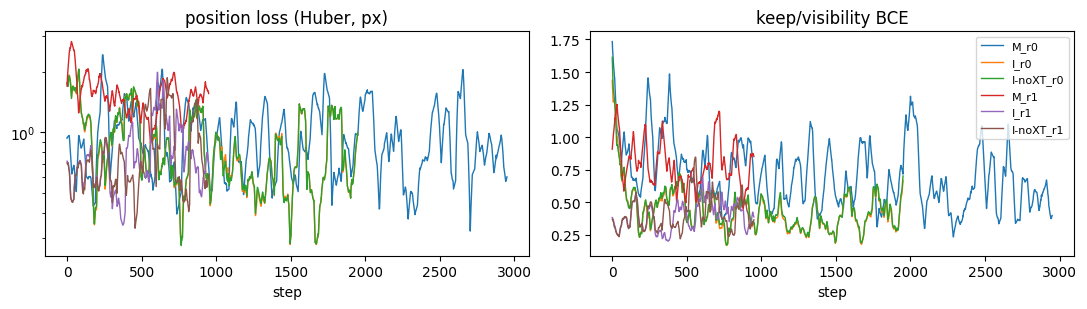

In [18]:
if HISTORY:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    for tag, hist in HISTORY.items():
        for ax, key in zip(axes, ("pos", "cls")):
            y = np.convolve([h[key] for h in hist], np.ones(50) / 50, mode="valid")
            ax.plot(y, label=tag, lw=1)
    axes[0].set(title="position loss (Huber, px)", xlabel="step", yscale="log")
    axes[1].set(title="keep/visibility BCE", xlabel="step")
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## Metrics
For every track, from the committed positions:
- **valid lifespan**: frames from birth until the first frame where the track is not (alive ∧ teacher-visible ∧ within δ of the
  teacher). It ends on drift, occlusion, or a drop. Still correct at the end of the clip → censored. Leaving the image together with
  the teacher's point → censored. Pooled over tracks with Kaplan–Meier and summarised as the restricted mean over 50 frames (RMST)
  and the median.
- **alive lifespan**: frames until the policy drops the track, ignoring correctness. This is plain survival, the number that is easy
  to inflate.
- **precision**: correct / alive track-frames (birth frames excluded).
- **zombie frames**: alive-but-wrong frames per track. **Premature drops**: share of tracks dropped while still correct.
- **coverage**: correct live tracks per frame. **Weight AUROC**: how well the per-track score separates correct from wrong track-frames.

In [19]:
HORIZON = 50

def kaplan_meier(L, event, horizon=HORIZON):
    """Discrete KM. L = frames survived (birth counts as 1). Event = ended in failure, otherwise censored. Returns S(a), a = 0..horizon."""
    S, s = np.ones(horizon + 1), 1.0
    for a in range(1, horizon + 1):
        n = np.sum(event & (L >= a)) + np.sum(~event & (L > a))
        if n:
            s *= 1 - np.sum(event & (L == a)) / n
        S[a] = s
    return S

def km_summary(L, event):
    S = kaplan_meier(L, event)
    below = np.where(S <= 0.5)[0]
    return S[:HORIZON].sum(), (below[0] if len(below) else np.inf), S

def track_stats(A, cols, q, vis, delta):
    """Per-track lifespans and frame-level counts for tracker columns `cols`, against labels q (T, n, 2) / vis (T, n)."""
    T = A["exists"].shape[0]
    used = A["exists"][:, cols].any(0)
    cols, q, vis = np.asarray(cols)[used], q[:, used], vis[:, used]
    ex, keep, score = A["exists"][:, cols], A["keep"][:, cols], A["score"][:, cols]
    t0 = A["seeds"][cols, 0].astype(int)
    n = len(cols)
    ar = np.arange(n)
    tt = np.arange(T)[:, None]
    correct = ex & vis & (np.linalg.norm(A["com"][:, cols] - q, axis=-1) < delta)
    after = tt > t0[None]

    last = T - 1 - np.argmax(ex[::-1], 0)                     # last alive frame
    dropped = ~keep[last, ar]
    La, ea = last - t0 + 1, dropped                           # alive lifespan; an event only if the policy dropped it

    bad = ~correct & (tt >= t0[None])
    end = np.where(bad.any(0), bad.argmax(0), T)              # first frame not correct
    Lv = end - t0
    endc = np.minimum(end, T - 1)
    alive_at_end = ex[endc, ar] & (end < T)
    left = (end < T) & ~alive_at_end & ~dropped & (last == end - 1)
    ev =(end < T) & ~(left & ~in_bounds(q[endc, ar]))         # leaving the image with the teacher's point is censored
    premature = (end < T) & ~alive_at_end & dropped & (last == end - 1)

    m = ex & after
    s, c = score[m], correct[m]
    auroc = roc_auc_score(c, s) if 0 < c.mean() < 1 and np.isfinite(s).all() else np.nan
    return dict(Lv=Lv, ev=ev, La=La, ea=ea, n=n, alive=m.sum(), correct=(correct & after).sum(),
                zombie=(ex & ~correct & after).sum(), premature=premature.sum(), frames=T,
                live_per_frame=ex.sum() / T, correct_per_frame=correct.sum() / T, auroc=auroc,
                err_correct=np.linalg.norm(A["com"][:, cols] - q, axis=-1)[correct & after].sum())

def aggregate(stats):
    cat = lambda k: np.concatenate([s[k] for s in stats])
    rmst_v, med_v, S_v = km_summary(cat("Lv"), cat("ev"))
    rmst_a, med_a, _ = km_summary(cat("La"), cat("ea"))
    tot = lambda k: sum(s[k] for s in stats)
    return dict(valid_RMST=rmst_v, valid_median=med_v, alive_RMST=rmst_a, alive_median=med_a,
                precision=tot("correct") / max(tot("alive"), 1), zombie_per_track=tot("zombie") / tot("n"),
                premature_drop=tot("premature") / tot("n"), correct_per_frame=tot("correct_per_frame") / len(stats),
                live_per_frame=tot("live_per_frame") / len(stats), weight_auroc=np.nanmean([s["auroc"] for s in stats]),
                err_correct_px=tot("err_correct") / max(tot("correct"), 1), tracks=tot("n"), S=S_v)

## Benchmark on 30 unseen clips
Baselines: FastKLT with its usual drop rule (LK status + forward–backward error ≤ 1 px), the same rule at other thresholds, status
only, and keep-all (only leaving the image ends a track). Reference: oracle rejection, which keeps exactly the correct tracks.
Learned: **M reject** (motion tokens, no correction), **M correct** (motion tokens with their consensus correction), **I correct**
(image tokens), **I no-xtrack** (image tokens without the kNN space blocks), each at keep thresholds τ ∈ {0.3, 0.5, 0.7}.
Every method runs the same tracker loop on the same seeds. TAP-Vid points ride along as probes.

In [ ]:
TAUS = (0.3, 0.5, 0.7)
DELTAS = (3.0, 6.0, 12.0)

def method_table():
    m = {f"KLT fb≤{th:g}": (lambda c, th=th: klt_policy(th)) for th in (0.25, 0.5, 1.0, 2.0, 4.0)}
    m["KLT status only"] = lambda c: klt_policy(np.inf)
    m["KLT keep-all"] = lambda c: klt_policy(np.inf, use_status=False)
    m["oracle reject"] = lambda c: oracle_policy(c["q"], c["vis"])
    for tau in TAUS:
        m[f"M reject τ={tau}"] = lambda c, tau=tau: model_policy(models["M"], tau, False)
        m[f"M correct τ={tau}"] = lambda c, tau=tau: model_policy(models["M"], tau, True)
        m[f"I correct τ={tau}"] = lambda c, tau=tau: model_policy(models["I"], tau, True, c["pyr"], c["tmpl"])
        m[f"I no-xtrack τ={tau}"] = lambda c, tau=tau: model_policy(models["I-noXT"], tau, True, c["pyr"], c["tmpl"])
    return m

def bench_clip(name, methods):
    path = f"{CACHE}/bench/{name}.pkl"
    done = pickle.load(open(path, "rb")) if os.path.exists(path) else {}
    todo = [k for k in methods if k not in done]
    if not todo:
        return done
    lab = label_video(name)
    frames, gray = load_video(name)
    probes, pq, pvis = gt_probes(name)
    Nc = len(lab["seeds"])
    allseeds = np.concatenate([lab["seeds"][:, :3], probes])
    pyr = feature_pyramid(frames)
    ctx = dict(pyr=pyr, tmpl=seed_templates(pyr, allseeds),
               q=np.concatenate([lab["q"], pq], 1), vis=np.concatenate([lab["vis"], pvis], 1))
    for k in todo:
        A = run_tracker(gray, lab["seeds"], methods[k](ctx), probes=probes)
        done[k] = dict(teacher={d: track_stats(A, np.arange(Nc), lab["q"], lab["vis"], d) for d in DELTAS},
                       gt=track_stats(A, Nc + np.arange(len(probes)), pq, pvis, cfg.delta_valid))
    pickle.dump(done, open(path, "wb"))
    return done

METHODS = method_table()
t_start = time.time()
BENCH = {name: bench_clip(name, METHODS) for name in tqdm(TEST, desc="benchmark")}
print(f"benchmark done ({time.time() - t_start:.0f}s)")

benchmark:   0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
def results_table(delta=cfg.delta_valid, labels="teacher"):
    rows = {}
    for k in METHODS:
        stats = [BENCH[n][k]["teacher"][delta] if labels == "teacher" else BENCH[n][k]["gt"] for n in TEST]
        rows[k] = {c: v for c, v in aggregate(stats).items() if c != "S"}
    return pd.DataFrame(rows).T

RES = results_table()
cols = ["valid_RMST", "valid_median", "alive_RMST", "precision", "zombie_per_track", "premature_drop",
        "correct_per_frame", "live_per_frame", "weight_auroc", "err_correct_px"]
RES[cols].round(3)

In [ ]:
def frontier_plot(res, ax, title):
    groups = [("KLT (fb threshold sweep)", [k for k in res.index if k.startswith("KLT")], "0.4", "o"),
              ("M reject", [k for k in res.index if k.startswith("M reject")], "tab:blue", "s"),
              ("M correct", [k for k in res.index if k.startswith("M correct")], "tab:cyan", "D"),
              ("I correct", [k for k in res.index if k.startswith("I correct")], "tab:red", "^"),
              ("I no-xtrack", [k for k in res.index if k.startswith("I no-xtrack")], "tab:orange", "v")]
    for label, ks, color, marker in groups:
        sub = res.loc[ks].sort_values("precision")
        ax.plot(sub["precision"], sub["valid_RMST"], marker=marker, color=color, label=label, lw=1.2)
    o = res.loc["oracle reject"]
    ax.scatter([o["precision"]], [o["valid_RMST"]], marker="*", s=150, color="k", label="oracle reject", zorder=5)
    ax.set(xlabel="track precision (correct / alive track-frames)", ylabel=f"valid lifespan, RMST over {HORIZON} frames", title=title)
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
frontier_plot(RES, axes[0], f"teacher labels, δ = {cfg.delta_valid:g}px")
frontier_plot(results_table(labels="gt"), axes[1], "TAP-Vid human labels (probes), δ = 6px")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

In [ ]:
SHOW = ["KLT fb≤1", "KLT keep-all", "oracle reject", "M reject τ=0.5", "M correct τ=0.5", "I correct τ=0.5", "I no-xtrack τ=0.5"]
fig, ax = plt.subplots(figsize=(7, 4.2))
for k in SHOW:
    S = aggregate([BENCH[n][k]["teacher"][cfg.delta_valid] for n in TEST])["S"]
    ax.step(np.arange(len(S)), S, where="post", label=k, lw=1.5, ls="--" if k in ("KLT keep-all", "oracle reject") else "-")
ax.set(xlabel="track age (frames)", ylabel="P(still alive and correct)", title="Kaplan–Meier survival of valid tracks", ylim=(0, 1.02))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Is the improvement real?
Paired over clips: per-clip valid RMST of each learned method minus FastKLT (fb ≤ 1), with a 95% bootstrap interval over clips, at
each δ. Also the same comparison against the TAP-Vid human labels.

In [ ]:
def per_clip_rmst(k, delta=None):
    out = []
    for n in TEST:
        s = BENCH[n][k]["gt"] if delta is None else BENCH[n][k]["teacher"][delta]
        out.append(km_summary(s["Lv"], s["ev"])[0])
    return np.array(out)

def paired(k, base="KLT fb≤1", delta=cfg.delta_valid, n_boot=10000):
    d = per_clip_rmst(k, delta) - per_clip_rmst(base, delta)
    boot = np.random.default_rng(0).choice(d, (n_boot, len(d))).mean(1)
    return f"{d.mean():+.2f} [{np.percentile(boot, 2.5):+.2f}, {np.percentile(boot, 97.5):+.2f}]"

learned = [k for k in METHODS if "τ=0.5" in k] + ["KLT keep-all", "oracle reject"]
pd.DataFrame({k: {**{f"Δ valid RMST, teacher δ={d:g}": paired(k, delta=d) for d in DELTAS},
                  "Δ valid RMST, TAP-Vid δ=6": paired(k, delta=None)} for k in learned}).T

In [ ]:
RES_GT = results_table(labels="gt")
RES_GT[cols].round(3)

### What it looks like
One test clip, last frame: tracks colored by how long they have been valid. FastKLT (left) vs the image arm (right).

In [ ]:
def show_tracks(name, keys, t=None):
    lab = label_video(name)
    frames, gray = load_video(name)
    t = len(frames) - 1 if t is None else t
    pyr = feature_pyramid(frames)
    ctx = dict(pyr=pyr, tmpl=seed_templates(pyr, lab["seeds"]), q=lab["q"], vis=lab["vis"])
    fig, axes = plt.subplots(1, len(keys), figsize=(6.5 * len(keys), 4))
    for ax, k in zip(axes, keys):
        A = run_tracker(gray, lab["seeds"], METHODS[k](ctx))
        ok = A["exists"] & lab["vis"] & (np.linalg.norm(A["com"] - lab["q"], axis=-1) < cfg.delta_valid)
        live = A["exists"][t]
        age_valid = np.zeros(ok.shape[1], int)       # consecutive correct frames ending at t
        for s in range(t + 1):
            age_valid = np.where(ok[s], age_valid + 1, 0)
        ax.imshow(frames[t])
        ax.scatter(*A["com"][t, live & ~ok[t]].T, s=10, c="red", marker="x", label="alive but wrong")
        sc = ax.scatter(*A["com"][t, live & ok[t]].T, s=10, c=age_valid[live & ok[t]], cmap="viridis", vmin=0, vmax=40)
        ax.set_title(f"{k}: {ok[t].sum()} correct, {(live & ~ok[t]).sum()} wrong")
        ax.axis("off")
    fig.colorbar(sc, ax=axes, label="frames valid so far", shrink=0.8)
    axes[0].legend(loc="lower left", fontsize=8)
    plt.show()

show_tracks(TEST[0], ["KLT fb≤1", "I correct τ=0.5"])

## Findings
_Filled in from the runs above._